載入資料庫中 (這可能需要幾秒鐘)...
建立極速查詢索引...
開始進行 個股高點回撤 15.0% 移動停利路徑模擬...
模擬完成！
------------------------------
【Rank 1 績效對決】
原始期望值 (死抱 20 天): 8.88%
動態移動停利 (回撤 15.0% 出場): 9.76%
------------------------------
------------------------------
【Rank 2 績效對決】
原始期望值 (死抱 20 天): 5.30%
動態移動停利 (回撤 15.0% 出場): 6.10%
------------------------------
------------------------------
【Rank 3 績效對決】
原始期望值 (死抱 20 天): 7.84%
動態移動停利 (回撤 15.0% 出場): 8.85%
------------------------------
------------------------------
【Rank 4 績效對決】
原始期望值 (死抱 20 天): 8.16%
動態移動停利 (回撤 15.0% 出場): 8.72%
------------------------------
------------------------------
【Rank 5 績效對決】
原始期望值 (死抱 20 天): 6.12%
動態移動停利 (回撤 15.0% 出場): 6.98%
------------------------------
開始計算日投組權益曲線與最大回撤 (含停利凍結效應)...


C:\Users\Lynn610\AppData\Local\Temp\ipykernel_1740\3447110802.py:132: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  period_df = period_df.fillna(method='ffill')
C:\Users\Lynn610\AppData\Local\Temp\ipykernel_1740\3447110802.py:132: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  period_df = period_df.fillna(method='ffill')
C:\Users\Lynn610\AppData\Local\Temp\ipykernel_1740\3447110802.py:132: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  period_df = period_df.fillna(method='ffill')
C:\Users\Lynn610\AppData\Local\Temp\ipykernel_1740\3447110802.py:132: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  period_df = period_df.fillna(meth

------------------------------
【系統風險觀測報告】
投組累積總報酬率 (加入停利後): 442.29%
日度最大回撤 (Daily MDD): -21.93%
------------------------------


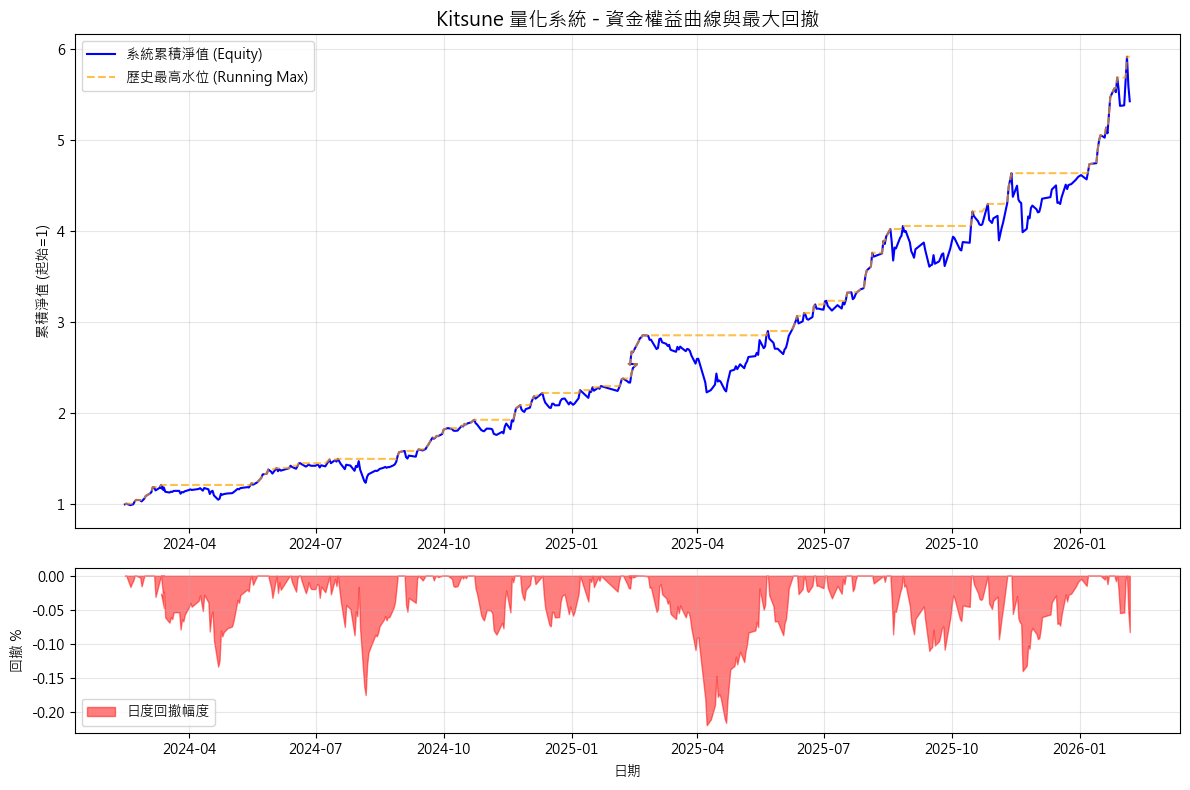

----------------------------------------
【系統參數最佳化掃描】
----------------------------------------
參數閥值: -10%
  [原始死抱] 期望值: 8.88%
  [固定停損] 期望值: 8.71%
  [移動停利] 期望值: 6.64%
----------------------------------------
參數閥值: -12%
  [原始死抱] 期望值: 8.88%
  [固定停損] 期望值: 8.13%
  [移動停利] 期望值: 9.80%
----------------------------------------
參數閥值: -15%
  [原始死抱] 期望值: 8.88%
  [固定停損] 期望值: 8.01%
  [移動停利] 期望值: 9.76%
----------------------------------------
參數閥值: -18%
  [原始死抱] 期望值: 8.88%
  [固定停損] 期望值: 7.87%
  [移動停利] 期望值: 8.41%
----------------------------------------


In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# 設定 matplotlib 支援中文顯示 (Windows 適用)
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 設定檔案路徑
trade_log_path = r"c:\Users\Lynn610\Documents\kitsune_stock_system\reports\backtest_tradelogs\trade_log_v16_rank_1_2_3_4_5.csv"
market_db_path = r"c:\Users\Lynn610\Documents\kitsune_stock_system\data\database\market.parquet"

print("載入資料庫中 (這可能需要幾秒鐘)...")
trade_df = pd.read_csv(trade_log_path)
market_df = pd.read_parquet(market_db_path)

trade_df.columns = trade_df.columns.str.lower().str.strip()
market_df.columns = market_df.columns.str.lower().str.strip()

# 欄位轉接頭與量級對齊
trade_df = trade_df.rename(columns={
    '換股日期': 'date',
    '股票代碼': 'id',
    '該股當月報酬%': 'return_20d',
    '排名': 'rank'
})

trade_df['return_20d'] = trade_df['return_20d'] / 100 

trade_df['date'] = pd.to_datetime(trade_df['date'])
market_df['date'] = pd.to_datetime(market_df['date'])
trade_df['id'] = trade_df['id'].astype(str).str.replace('.0', '', regex=False)
market_df['id'] = market_df['id'].astype(str)

print("建立極速查詢索引...")
market_df = market_df.sort_values(['id', 'date']).set_index(['id', 'date'])

# 準備新欄位記錄停利狀態
trade_df['return_20d_SL15'] = trade_df['return_20d']
trade_df['stop_date'] = pd.NaT  # 紀錄觸發出場的日期
trade_df['stop_price'] = np.nan # 紀錄觸發出場的價格

stop_loss_threshold = 0.15

print(f"開始進行 個股高點回撤 {stop_loss_threshold*100}% 移動停利路徑模擬...")

for idx, row in trade_df.iterrows():
    stock_id = row['id']
    entry_date = row['date']
    
    try:
        future_data = market_df.loc[stock_id].loc[entry_date:]
        if len(future_data) > 0:
            future_20d = future_data.head(20)
            entry_price = future_20d.iloc[0]['close']
            
            # 🌟 核心修改 1：錨點改為追蹤「波段最高收盤價」 (Highest Close)
            # 這能完美過濾掉盤中主力亂拉的上影線雜訊
            running_max_close = future_20d['close'].cummax()
            
            # 🌟 核心修改 2：用盤中的「最低價」去撞擊收盤價防線
            # 模擬真實世界的智慧觸價單：盤中只要一跌破最高收盤價的 15%，立刻觸發
            trailing_dd = (future_20d['low'] / running_max_close) - 1
            
            # 判斷是否觸發 -15% 移動停利/停損
            hit_mask = trailing_dd <= -stop_loss_threshold
            
            if hit_mask.any():
                # 找出觸發的第一天
                hit_date = hit_mask.idxmax()
                
                # 計算觸發當下的絕對價格 (最高收盤價的 85%)
                trigger_price = running_max_close.loc[hit_date] * (1 - stop_loss_threshold)
                
                # 結算這筆交易的最終報酬
                trade_df.at[idx, 'return_20d'] = (trigger_price / entry_price) - 1
                
                # 若需要紀錄出場資訊，可以保留這兩行（需確保 trade_df 有先建立這兩個欄位）
                # trade_df.at[idx, 'stop_date'] = hit_date
                # trade_df.at[idx, 'stop_price'] = trigger_price
                
    except KeyError:
        pass

print("模擬完成！")

for i in range(1,6):
    rank1_original = trade_df[trade_df['rank'] == i]['return_20d'].mean() * 100
    rank1_with_sl = trade_df[trade_df['rank'] == i]['return_20d_SL15'].mean() * 100

    print("-" * 30)
    print(f"【Rank {i} 績效對決】")
    print(f"原始期望值 (死抱 20 天): {rank1_original:.2f}%")
    print(f"動態移動停利 (回撤 {stop_loss_threshold*100}% 出場): {rank1_with_sl:.2f}%")
    print("-" * 30)

# ==========================================
# 繪製日投組權益曲線與最大回撤
# ==========================================
print("開始計算日投組權益曲線與最大回撤 (含停利凍結效應)...")

portfolio_daily_curves = []
grouped_trades = trade_df.groupby('date')

for entry_date, group in grouped_trades:
    period_prices = []
    
    for _, row in group.iterrows():
        stock_id = row['id']
        stop_date = row['stop_date']
        stop_price = row['stop_price']
        
        try:
            future_data = market_df.loc[stock_id].loc[entry_date:].head(20)
            if not future_data.empty:
                prices = future_data['close'].copy()
                
                # 如果這檔股票有觸發停利，將觸發日之後的價格凍結在 stop_price (轉為現金)
                if pd.notna(stop_date):
                    # 找出觸發日之後的日期並覆寫價格
                    mask_after_stop = prices.index >= stop_date
                    prices.loc[mask_after_stop] = stop_price
                
                normalized_price = prices / prices.iloc[0]
                period_prices.append(normalized_price)
        except KeyError:
            continue
            
    if period_prices:
        period_df = pd.concat(period_prices, axis=1)
        period_df = period_df.fillna(method='ffill') 
        
        period_portfolio_curve = period_df.mean(axis=1)
        period_daily_returns = period_portfolio_curve.pct_change().fillna(0)
        
        if len(portfolio_daily_curves) > 0:
            period_daily_returns = period_daily_returns.iloc[1:]
            
        portfolio_daily_curves.append(period_daily_returns)

all_daily_returns = pd.concat(portfolio_daily_curves)
equity_curve = (1 + all_daily_returns).cumprod()
running_max = equity_curve.cummax()
daily_drawdown = (equity_curve / running_max) - 1
mdd = daily_drawdown.min()

print("-" * 30)
print("【系統風險觀測報告】")
print(f"投組累積總報酬率 (加入停利後): {(equity_curve.iloc[-1] - 1) * 100:.2f}%")
print(f"日度最大回撤 (Daily MDD): {mdd * 100:.2f}%")
print("-" * 30)

# ==========================================
# 產生視覺化圖表
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [3, 1]})

# 上半部：權益曲線
ax1.plot(equity_curve.index, equity_curve.values, color='blue', linewidth=1.5, label='系統累積淨值 (Equity)')
ax1.plot(running_max.index, running_max.values, color='orange', linestyle='--', alpha=0.7, label='歷史最高水位 (Running Max)')
ax1.set_title('Kitsune 量化系統 - 資金權益曲線與最大回撤', fontsize=14)
ax1.set_ylabel('累積淨值 (起始=1)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# 下半部：回撤深度圖
ax2.fill_between(daily_drawdown.index, daily_drawdown.values, 0, color='red', alpha=0.5, label='日度回撤幅度')
ax2.set_ylabel('回撤 %')
ax2.set_xlabel('日期')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

# ==========================================
# 參數最佳化掃描：固定停損 vs 移動停利
# ==========================================
print("-" * 40)
print("【系統參數最佳化掃描】")
print("-" * 40)

thresholds = [0.10, 0.12, 0.15, 0.18]

for thresh in thresholds:
    col_fixed = f'fixed_sl_{thresh}'
    col_trail = f'trail_sl_{thresh}'
    
    trade_df[col_fixed] = trade_df['return_20d']
    trade_df[col_trail] = trade_df['return_20d']

    for idx, row in trade_df.iterrows():
        stock_id = row['id']
        entry_date = row['date']
        try:
            future_data = market_df.loc[stock_id].loc[entry_date:].head(20)
            if len(future_data) > 0:
                entry_price = future_data.iloc[0]['close']
                
                # 1. 固定停損：從進場價計算的跌幅
                fixed_dd = (future_data['low'] / entry_price) - 1
                if (fixed_dd <= -thresh).any():
                    trade_df.at[idx, col_fixed] = -thresh
                    
                # 2. 移動停利：從歷史最高價計算的跌幅
                running_max = future_data['high'].cummax()
                trail_dd = (future_data['low'] / running_max) - 1
                if (trail_dd <= -thresh).any():
                    hit_date = (trail_dd <= -thresh).idxmax()
                    trigger_price = running_max.loc[hit_date] * (1 - thresh)
                    trade_df.at[idx, col_trail] = (trigger_price / entry_price) - 1
        except KeyError:
            pass

    # 以最核心的 Rank 1 作為基準評估
    base_exp = trade_df[trade_df['rank'] == 1]['return_20d'].mean() * 100
    fixed_exp = trade_df[trade_df['rank'] == 1][col_fixed].mean() * 100
    trail_exp = trade_df[trade_df['rank'] == 1][col_trail].mean() * 100
    
    print(f"參數閥值: -{thresh*100:.0f}%")
    print(f"  [原始死抱] 期望值: {base_exp:.2f}%")
    print(f"  [固定停損] 期望值: {fixed_exp:.2f}%")
    print(f"  [移動停利] 期望值: {trail_exp:.2f}%")
    print("-" * 40)

📥 正在下載 Taiwan TAIEX (大盤) (^TWII) 過去 3 年資料...


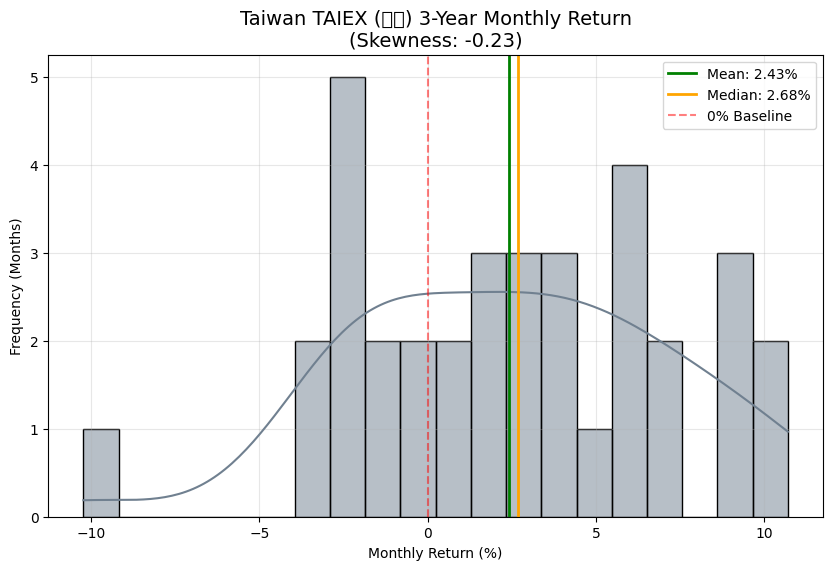

✅ Taiwan TAIEX (大盤) 過去 3 年偏態係數: -0.23
   平均數 (Mean): 2.43%
   中位數 (Median): 2.68%

📥 正在下載 Taiwan TAIEX (大盤) (^TWII) 過去 10 年資料...


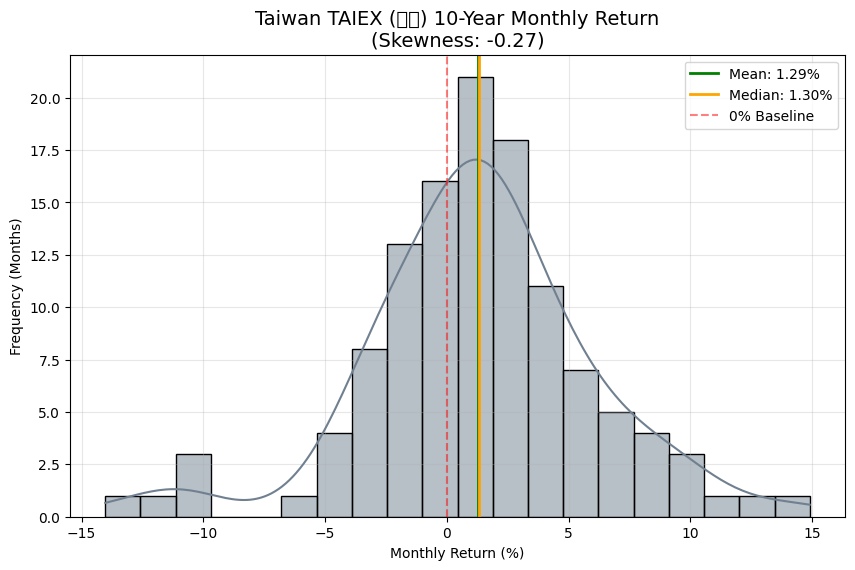

✅ Taiwan TAIEX (大盤) 過去 10 年偏態係數: -0.27
   平均數 (Mean): 1.29%
   中位數 (Median): 1.30%



In [3]:
# 大盤偏態 (新增平均數、中位數標示)
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore') # 忽略一些 yfinance 的警告

def analyze_market_skewness(ticker, name, years=3):
    print(f"📥 正在下載 {name} ({ticker}) 過去 {years} 年資料...")
    
    # 1. 設定時間範圍
    end_date = datetime.now()
    start_date = end_date - timedelta(days=years*365)
    
    # 2. 下載資料
    df = yf.download(ticker, start=start_date, end=end_date, progress=False)
    
    # 處理 yfinance 可能回傳 MultiIndex 的情況
    if isinstance(df.columns, pd.MultiIndex):
        close_price = df['Close'][ticker]
    else:
        close_price = df['Close']
        
    # 3. 轉換為「月報酬率」
    monthly_returns = close_price.resample('ME').last().pct_change().dropna() * 100
    
    # 4. 計算統計數值
    skewness_value = monthly_returns.skew()
    mean_val = monthly_returns.mean()     # 新增：平均數
    median_val = monthly_returns.median() # 新增：中位數
    
    # 5. 繪製帶有平滑曲線的直方圖 (KDE)
    plt.figure(figsize=(10, 6))
    sns.histplot(monthly_returns, bins=20, kde=True, color='slategray')
    
    plt.title(f"{name} {years}-Year Monthly Return\n(Skewness: {skewness_value:.2f})", fontsize=14)
    plt.xlabel("Monthly Return (%)")
    plt.ylabel("Frequency (Months)")
    
    # 🌟 新增：畫出平均數(綠線)、中位數(橘線)與 0%基準線(紅虛線)
    plt.axvline(mean_val, color='green', linestyle='-', linewidth=2, label=f'Mean: {mean_val:.2f}%')
    plt.axvline(median_val, color='orange', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}%')
    plt.axvline(0, color='red', linestyle='--', alpha=0.5, label='0% Baseline')
    
    plt.legend() # 顯示圖例
    plt.grid(alpha=0.3)
    plt.show()
    
    print(f"✅ {name} 過去 {years} 年偏態係數: {skewness_value:.2f}")
    print(f"   平均數 (Mean): {mean_val:.2f}%")
    print(f"   中位數 (Median): {median_val:.2f}%\n")

if __name__ == '__main__':
    # 測試 1：加權指數 (大盤) 過去 3 年
    analyze_market_skewness('^TWII', 'Taiwan TAIEX (大盤)', years=3)
    
    # 🛡️ 測試 2：加權指數 (大盤) 過去 10 年
    analyze_market_skewness('^TWII', 'Taiwan TAIEX (大盤)', years=10)

C:\Users\Lynn610\AppData\Local\Temp\ipykernel_2812\71514994.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(['{:,.0%}'.format(x) for x in vals])


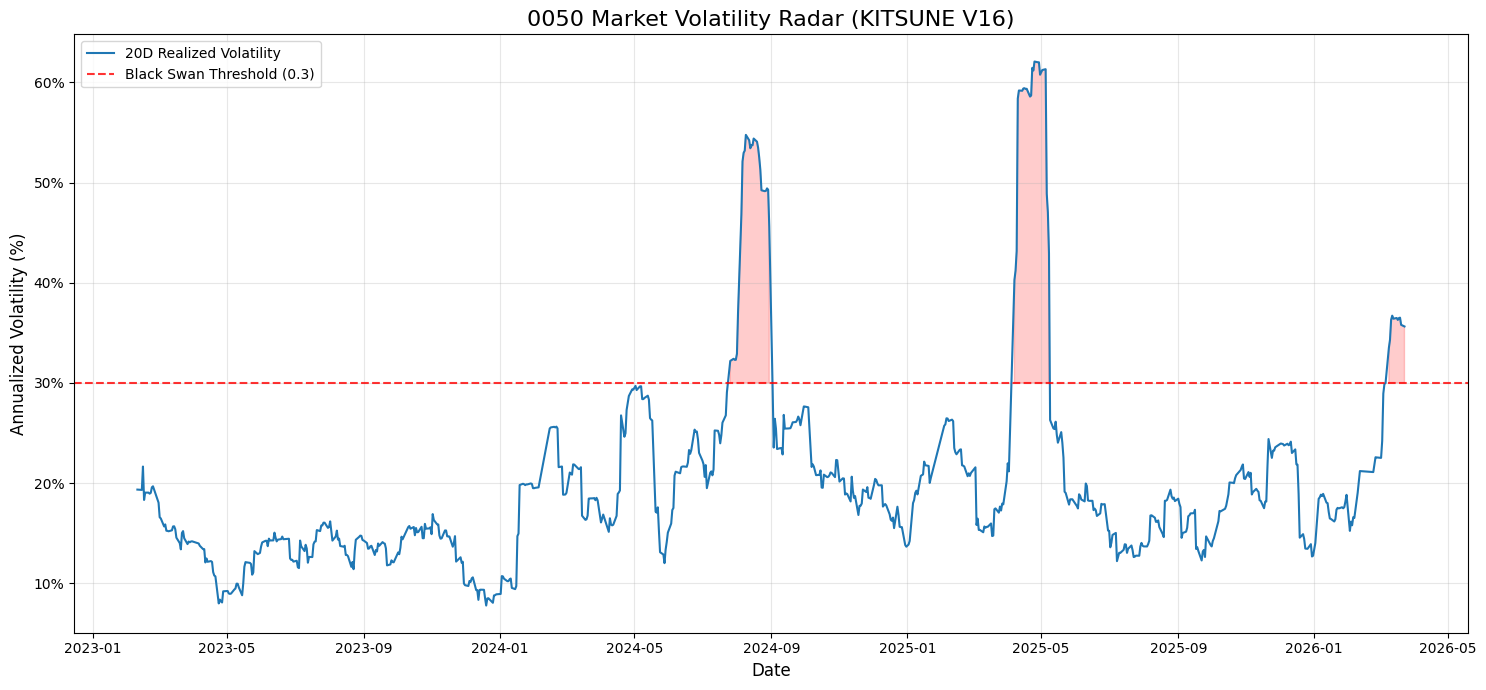

2024-07-26 00:00:00
2024-07-29 00:00:00
2024-07-30 00:00:00
2024-07-31 00:00:00
2024-08-01 00:00:00
2024-08-02 00:00:00
2024-08-05 00:00:00
2024-08-06 00:00:00
2024-08-07 00:00:00
2024-08-08 00:00:00
2024-08-09 00:00:00
2024-08-12 00:00:00
2024-08-13 00:00:00
2024-08-14 00:00:00
2024-08-15 00:00:00
2024-08-16 00:00:00
2024-08-19 00:00:00
2024-08-20 00:00:00
2024-08-21 00:00:00
2024-08-22 00:00:00
2024-08-23 00:00:00
2024-08-26 00:00:00
2024-08-27 00:00:00
2024-08-28 00:00:00
2024-08-29 00:00:00
2024-08-30 00:00:00
2025-04-07 00:00:00
2025-04-08 00:00:00
2025-04-09 00:00:00
2025-04-10 00:00:00
2025-04-11 00:00:00
2025-04-14 00:00:00
2025-04-15 00:00:00
2025-04-16 00:00:00
2025-04-17 00:00:00
2025-04-18 00:00:00
2025-04-21 00:00:00
2025-04-22 00:00:00
2025-04-23 00:00:00
2025-04-24 00:00:00
2025-04-25 00:00:00
2025-04-28 00:00:00
2025-04-29 00:00:00
2025-04-30 00:00:00
2025-05-02 00:00:00
2025-05-05 00:00:00
2025-05-06 00:00:00
2025-05-07 00:00:00
2025-05-08 00:00:00
2026-03-09 00:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# 1. 取得資料 (優先讀取你的本地 0050.csv，若無則從 yfinance 下載)
try:
    # 假設你的檔案路徑符合之前的設定
    df_0050 = pd.read_csv(r"c:\Users\Lynn610\Documents\kitsune_stock_system\data\database\0050.csv") # 請根據實際路徑修改
    df_0050['date'] = pd.to_datetime(df_0050['date'])
    df_0050 = df_0050.sort_values('date').set_index('date')
    price_col = 'price' if 'price' in df_0050.columns else 'close'
except:
    print("找不到本地檔案，改從 yfinance 下載最新資料...")
    df_0050 = yf.download("0050.TW", start="2023-01-01")
    price_col = 'Close'

# 2. 計算波動率邏輯
# 華爾街標準：日報酬標準差 * 根號 252 (一年交易日)
df_0050['daily_return'] = df_0050[price_col].pct_change()
df_0050['realized_vol'] = df_0050['daily_return'].rolling(window=20).std() * np.sqrt(252)

# 3. 繪圖
plt.figure(figsize=(15, 7))

# 畫出波動率曲線
plt.plot(df_0050.index, df_0050['realized_vol'], label='20D Realized Volatility', color='#1f77b4', linewidth=1.5)

# 畫出 0.3 (30%) 的斷路器閾值
plt.axhline(y=0.3, color='red', linestyle='--', alpha=0.8, label='Black Swan Threshold (0.3)')

# 填色區塊 (超過 0.3 的區域)
plt.fill_between(df_0050.index, df_0050['realized_vol'], 0.3, 
                 where=(df_0050['realized_vol'] >= 0.3), color='red', alpha=0.2)

# 圖表美化
plt.title('0050 Market Volatility Radar (KITSUNE V16)', fontsize=16)
plt.ylabel('Annualized Volatility (%)', fontsize=12)
plt.xlabel('Date', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

# 將 Y 軸顯示為百分比格式
vals = plt.gca().get_yticks()
plt.gca().set_yticklabels(['{:,.0%}'.format(x) for x in vals])

plt.tight_layout()
plt.show()

high_vol_dates = df_0050[df_0050['realized_vol'] > 0.3].index
for d in high_vol_dates:
    print(d)